# 28 - Betting verdict: strategy shoot-out and multiple testing (P8-07)

P8-03..06 each picked one rule on the tuning seasons (22-23/23-24) before seeing
anything else. This notebook puts those rules next to the P8-02 baselines on the
report seasons (24-25/25-26) and on 26-27 to date, then asks how likely it is
that the best result is luck, given that roughly 800 variants were tried.
**There is no new tuning here.** Every rule and parameter comes from the earlier notebooks.

- **Inputs** (written by notebooks 25 and 27):
  `betting_variants.csv` (one summary row per variant x source x period),
  `betting_variant_weeks.csv.gz` (each variant's profit and stake per betting week),
  `betting_chosen_bets.csv` (the individual bets of each chosen rule).
- **Prices:** opening odds. `avg` = market average, `b365` = one real bookmaker,
  `max` = best price across bookmakers. `max` is an optimistic bound because you can't
  reliably get it.
- **Uncertainty:** week-block bootstrap (5,000 resamples, seed 42), as in every P8 ticket.

**Gate (from the ticket):**
- **Profitable:** report-season ROI 95% CI lower bound > 0 at `avg` or `b365`, survives the
  multiple-testing correction, mean CLV > 0, and profitable in both report seasons.
- **Promising:** point ROI > 0 in both report seasons and CLV > 0, but the CI crosses 0.
  This leads to paper trading (P8-08), not real money.
- **No edge:** anything else.

In [1]:
import os
import re
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from betting.market import prices
from betting.simulate import N_BOOT, SEED, bootstrap_roi, flat_argmax, load_oos, simulate, single, summarise
from betting.variants import load_chosen_bets, load_variant_weeks, load_variants

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 200)

TEST = ["22-23", "23-24", "24-25", "25-26"]
TUNE, REPORT = TEST[:2], TEST[2:]
CURRENT = "26-27"
PERIODS = {"tune": TUNE, "report": REPORT, "26-27": [CURRENT]}
SOURCES = ["avg", "b365", "max"]
OUTCOMES = ["H", "D", "A"]
TUNE_COLOUR, REPORT_COLOUR, CURRENT_COLOUR = "#2a78d6", "#eb6834", "#1baf7a"

def style(ax):
    ax.grid(axis="y", color="#dddddd", linewidth=0.6)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

## Data

Betting weeks come from `oos_predictions.csv`, in kick-off order, as in notebooks
25 and 27. A week without a bet counts as a week with zero stake.

In [2]:
oos = load_oos()
oos = oos[oos["FTR"].notna()]
oos = oos.sort_values(["MatchDateTime", "Div", "HomeTeam"], kind="stable").reset_index(drop=True)
oos["Week"] = oos["Season"] + "|" + oos["BetWeek"]
PERIOD_WEEKS = {name: list(pd.unique(oos.loc[oos["Season"].isin(s), "Week"])) for name, s in PERIODS.items()}
SEASON_WEEKS = {s: list(pd.unique(oos.loc[oos["Season"] == s, "Week"])) for s in TEST + [CURRENT]}

variants = load_variants()
weeks_log = load_variant_weeks()
chosen_bets = load_chosen_bets()

selection = variants[~variants["family"].str.contains("staking")]
counts = pd.DataFrame({
    "selection variants": selection.groupby("ticket")["variant"].nunique(),
    "staking runs": variants[variants["family"].str.contains("staking")].groupby("ticket")["variant"].nunique(),
    "with weekly P&L": weeks_log.groupby("ticket")["variant"].nunique(),
}).fillna(0).astype(int)
counts.loc["total"] = counts.sum()
print({k: len(v) for k, v in PERIOD_WEEKS.items()}, "betting weeks per period")
counts

{'tune': 77, 'report': 77, '26-27': 11} betting weeks per period


,selection variants,staking runs,with weekly P&L
ticket,,,
P8-03,274,0,257
P8-04,321,10,321
P8-05,67,0,66
P8-06,126,8,111
total,788,18,755


## The contenders

The P8-02 baselines (flat 1 unit on every match) and the one rule each ticket
chose on the tuning seasons:

| Ticket | Pre-registered rule |
|---|---|
| P8-03 | P1 (Primeira Liga) argmax picks with p >= 0.475 |
| P8-04 | Value bets on the blended probability, edge >= 0, odds <= 2.5 |
| P8-05 | Acca of the week's 8 most confident picks with odds >= 1.50 |
| P8-06 | O/U 2.5: the side with fair probability >= 0.675 |
| P8-06 | Asian handicap: the side with fair probability >= 0.675 |

The baselines are rebuilt here as per-bet tables. The market favourite and model
argmax are checked against `simulate()`, and the chosen rules' bet tables against
the variant log.

In [3]:
def priced_1x2(source):
    pairs = [prices(oos, source, "1X2", sel) for sel in OUTCOMES]
    return (np.column_stack([o.to_numpy(float) for o, _ in pairs]),
            np.column_stack([c.to_numpy(float) for _, c in pairs]))

Y = pd.Categorical(oos["FTR"], categories=OUTCOMES).codes
P_MODEL = oos[["pH", "pD", "pA"]].to_numpy(float)
ARGMAX = np.array([2, 1, 0])[oos[["pA", "pD", "pH"]].to_numpy().argmax(axis=1)]  # A, D, H tie order as backtest.py

def baseline_bets(name, source):
    odds3, close3 = priced_1x2(source)
    if name == "market favourite":
        sel = np.nanargmin(np.where(np.isfinite(odds3), odds3, np.inf), axis=1)
    elif name == "model argmax":
        sel = ARGMAX
    else:
        sel = np.full(len(oos), {"always home": 0, "always draw": 1, "always away": 2}[name])
    rows = np.arange(len(oos))
    odds, closing = odds3[rows, sel], close3[rows, sel]
    ok = np.isfinite(odds) & (odds > 1)
    with np.errstate(divide="ignore", invalid="ignore"):
        clv = np.log(odds / closing)
    return pd.DataFrame({
        "ticket": "P8-02", "rule": name, "source": source, "Season": oos["Season"], "Week": oos["Week"],
        "Div": oos["Div"], "MatchKey": oos["MatchKey"], "selection": np.array(OUTCOMES)[sel], "odds": odds,
        "stake": 1.0, "profit": np.where(Y == sel, odds - 1, -1.0), "clv": np.where(np.isfinite(clv), clv, np.nan),
    })[ok]

BASELINES = ["market favourite", "model argmax", "always home", "always draw", "always away"]
bets = pd.concat([baseline_bets(b, s) for b in BASELINES for s in SOURCES] + [chosen_bets], ignore_index=True)

# Check 1: favourite and argmax baselines = simulate()
def favourite(week, bankroll):
    odds = week[["oH", "oD", "oA"]].to_numpy(dtype=float)
    picks = np.array(OUTCOMES)[np.nanargmin(np.where(np.isfinite(odds), odds, np.inf), axis=1)]
    return [single(k, p, 1.0) for k, p in zip(week["MatchKey"], picks)]

test = oos[oos["Season"].isin(TEST)]
for name, strategy in [("market favourite", favourite), ("model argmax", flat_argmax)]:
    for source in ["avg", "b365"]:
        sim = summarise(simulate(test, strategy, source=source)).loc["overall"]
        b = bets[(bets["rule"] == name) & (bets["source"] == source) & bets["Season"].isin(TEST)]
        assert len(b) == sim["bets"] and abs(round(b["profit"].sum(), 2) - sim["profit"]) < 0.011, (name, source)

# Check 2: chosen-rule bet tables = the variant log (bets and ROI per period and source)
CHOSEN = {
    "P8-03": ("P8-03", "P1 p>=0.475"),
    "P8-04": ("P8-04", "blend e>=0.00 odds <=2.5"),
    "P8-05": ("P8-05", "top 8 by p, odds>=1.50"),
    "P8-06 O/U": ("P8-06", "OU25 p>=0.675"),
    "P8-06 AH": ("P8-06", "AH p>=0.675"),
}
assert set(chosen_bets["rule"]) == {v for _, v in CHOSEN.values()}, set(chosen_bets["rule"])
for label, (ticket, variant) in CHOSEN.items():
    for source in SOURCES:
        for period, seasons in PERIODS.items():
            row = variants[(variants["ticket"] == ticket) & (variants["variant"] == variant)
                           & (variants["source"] == source) & (variants["period"] == period)].iloc[0]
            b = chosen_bets[(chosen_bets["rule"] == variant) & (chosen_bets["source"] == source) & chosen_bets["Season"].isin(seasons)]
            assert len(b) == row["bets"], (label, source, period)
            if len(b):
                assert abs(b["profit"].sum() / b["stake"].sum() * 100 - row["roi"]) < 1e-6, (label, source, period)
print("Baselines match simulate(); chosen-rule bets match the variant log")
CONTENDERS = {**{b: b for b in BASELINES}, **{label: v for label, (_, v) in CHOSEN.items()}}

Baselines match simulate(); chosen-rule bets match the variant log


## Shoot-out: report seasons 24-25/25-26 and 26-27 to date

Flat 1 unit a bet. `ROI [95% CI]` uses the week-block bootstrap. `CLV` is the mean
log(taken / closing) price as a percentage. For P8-05 it's the mean over legs.
`max DD` is the largest peak-to-trough fall in cumulative profit over the
period's weeks, in units. `seasons +` counts report seasons in profit.

In [4]:
def week_frame(b, weeks):
    return (b.groupby("Week")[["profit", "stake"]].sum().rename(columns={"stake": "staked"})
            .reindex(weeks, fill_value=0.0))

def metrics(b, period):
    weeks = PERIOD_WEEKS[period]
    b = b[b["Week"].isin(set(weeks))]
    if b.empty:
        return {"bets": 0}
    w = week_frame(b, weeks)
    boot = bootstrap_roi(w)
    cum = np.concatenate([[0.0], np.cumsum(w["profit"].to_numpy())])
    per_season = b.groupby("Season").apply(lambda d: d["profit"].sum() / d["stake"].sum() * 100)
    return {
        "bets": len(b), "bets_per_week": len(b) / len(weeks), "avg_odds": b["odds"].mean(),
        "roi": b["profit"].sum() / b["stake"].sum() * 100,
        "roi_ci_low": boot["ci"][0] * 100, "roi_ci_high": boot["ci"][1] * 100,
        "clv": b["clv"].mean() * 100, "profit": b["profit"].sum(),
        "max_dd": float((np.maximum.accumulate(cum) - cum).max()),
        **{f"roi {s}": per_season.get(s, np.nan) for s in PERIODS[period]},
        "seasons +": int((b.groupby("Season")["profit"].sum() > 0).sum()),
    }

rows = []
for label, rule in CONTENDERS.items():
    for source in SOURCES:
        b = bets[(bets["rule"] == rule) & (bets["source"] == source)]
        for period in PERIODS:
            rows.append({"rule": label, "source": source, "period": period, **metrics(b, period)})
shoot = pd.DataFrame(rows)

def fmt(r):
    return f"{r['roi']:+.1f} [{r['roi_ci_low']:+.1f}, {r['roi_ci_high']:+.1f}]" if r["bets"] else ""

shoot["ROI [CI]"] = shoot.apply(fmt, axis=1)
rep = shoot[shoot["period"] == "report"]
table = rep.pivot_table(index="rule", columns="source", values="ROI [CI]", aggfunc="first")[SOURCES]
avg = rep[rep["source"] == "avg"].set_index("rule")
for col, name in [("bets_per_week", "bets/wk"), ("clv", "CLV avg"), ("max_dd", "max DD avg"),
                  ("roi 24-25", "24-25 avg"), ("roi 25-26", "25-26 avg"), ("seasons +", "seasons + avg")]:
    table[name] = avg[col].round(2)
cur = shoot[(shoot["period"] == "26-27")].pivot_table(index="rule", columns="source", values="ROI [CI]", aggfunc="first")
table["26-27 avg"], table["26-27 b365"] = cur["avg"], cur["b365"]
table = table.reindex(list(CONTENDERS))
print("REPORT SEASONS 24-25/25-26 (ROI %, flat 1u)")
table

REPORT SEASONS 24-25/25-26 (ROI %, flat 1u)


source,avg,b365,max,bets/wk,CLV avg,max DD avg,24-25 avg,25-26 avg,seasons + avg,26-27 avg,26-27 b365
rule,,,,,,,,,,,
market favourite,"-3.8 [-6.4, -1.3]","-4.3 [-6.8, -1.9]","-1.2 [-3.9, +1.3]",61.40,-0.56,184.56,-4.32,-3.25,0,"-3.8 [-12.4, +5.0]","-3.4 [-12.0, +5.4]"
model argmax,"-6.0 [-8.8, -3.4]","-6.0 [-8.7, -3.4]","-3.2 [-6.1, -0.5]",61.40,-0.50,283.61,-5.23,-6.72,0,"-2.3 [-8.1, +3.8]","-1.7 [-7.4, +4.2]"
always home,"-10.1 [-13.8, -6.5]","-9.8 [-13.5, -6.3]","-6.6 [-10.5, -2.8]",61.40,-1.15,478.77,-11.09,-9.06,0,"-9.1 [-21.1, +1.8]","-7.9 [-19.9, +3.0]"
always draw,"-3.2 [-8.0, +1.7]","-3.1 [-7.8, +1.8]","+1.4 [-3.6, +6.6]",61.40,0.60,219.29,-3.11,-3.36,0,"-7.4 [-23.7, +10.1]","-7.0 [-23.3, +10.7]"
always away,"-10.1 [-14.9, -5.3]","-9.6 [-14.4, -4.9]","-5.4 [-10.6, -0.2]",61.40,-0.95,481.09,-7.08,-13.03,0,"-8.7 [-20.8, +3.7]","-6.4 [-18.7, +6.3]"
P8-03,"-5.5 [-14.2, +3.2]","-6.1 [-14.7, +2.5]","-3.0 [-11.9, +6.0]",5.31,0.19,26.09,-7.92,-3.26,0,"-0.9 [-23.3, +23.4]","-2.3 [-24.1, +21.5]"
P8-04,"-3.4 [-8.3, +1.1]","-5.6 [-9.9, -1.1]","-0.8 [-3.5, +1.9]",15.87,0.08,64.15,-3.19,-4.37,0,"-5.4 [-65.8, +42.0]","+13.9 [-5.6, +33.4]"
P8-05,"-100.0 [-100.0, -100.0]","-49.0 [-100.0, +57.1]","-46.6 [-100.0, +64.5]",0.99,-0.12,76.00,-100.00,-100.00,0,"-100.0 [-100.0, -100.0]","-100.0 [-100.0, -100.0]"
P8-06 O/U,"-3.1 [-8.8, +2.4]","-2.3 [-8.1, +3.2]","-0.8 [-6.7, +4.8]",4.97,0.25,17.75,-1.64,-4.61,0,"-4.2 [-12.9, +5.5]","-2.5 [-11.5, +7.6]"


In [5]:
# Tuning seasons for context (the chosen rules were picked on these)
tune_tab = shoot[shoot["period"] == "tune"].pivot_table(index="rule", columns="source", values="ROI [CI]", aggfunc="first")[SOURCES]
tune_tab["bets/wk"] = shoot[(shoot["period"] == "tune") & (shoot["source"] == "avg")].set_index("rule")["bets_per_week"].round(1)
tune_tab.reindex(list(CONTENDERS))

source,avg,b365,max,bets/wk
rule,,,,
market favourite,"+0.3 [-2.3, +2.9]","-0.4 [-2.9, +2.1]","+3.5 [+0.8, +6.1]",62.4
model argmax,"+0.3 [-2.1, +2.7]","-0.6 [-2.9, +1.8]","+3.4 [+1.0, +5.9]",62.4
always home,"-5.8 [-9.6, -1.9]","-6.6 [-10.3, -2.7]","-2.0 [-6.1, +2.2]",62.4
always draw,"-3.6 [-8.2, +1.5]","-4.4 [-9.1, +0.6]","+1.7 [-3.3, +7.1]",62.4
always away,"-13.8 [-18.0, -9.8]","-14.2 [-18.4, -10.2]","-9.1 [-13.6, -4.7]",62.4
P8-03,"+6.1 [-1.1, +13.3]","+5.4 [-1.7, +12.6]","+8.8 [+1.4, +16.2]",4.7
P8-04,"-0.8 [-4.3, +2.7]","-2.4 [-6.7, +2.0]","+2.5 [+0.0, +5.0]",27.3
P8-05,"+210.9 [-100.0, +845.3]","+192.5 [-100.0, +789.2]","+313.6 [-100.0, +1157.7]",1.0
P8-06 O/U,"+1.7 [-4.6, +7.5]","+1.6 [-4.7, +7.5]","+4.4 [-2.1, +10.4]",5.8


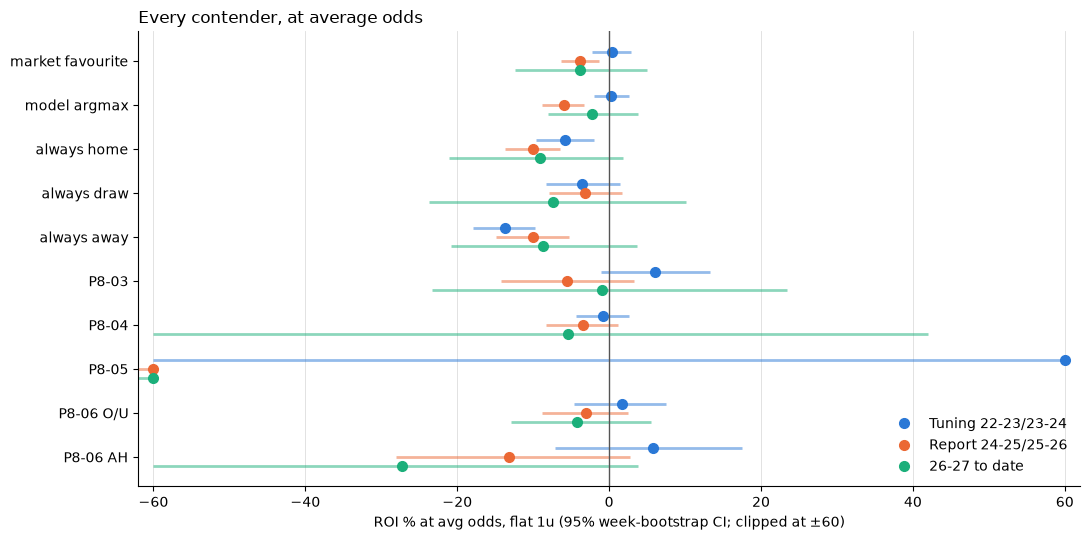

In [6]:
fig, ax = plt.subplots(figsize=(11, 5.5))
order = list(CONTENDERS)
y = np.arange(len(order))
for offset, (period, colour, label) in zip([-0.2, 0.0, 0.2], [("tune", TUNE_COLOUR, "Tuning 22-23/23-24"),
                                                              ("report", REPORT_COLOUR, "Report 24-25/25-26"),
                                                              ("26-27", CURRENT_COLOUR, "26-27 to date")]):
    d = shoot[(shoot["period"] == period) & (shoot["source"] == "avg")].set_index("rule").reindex(order)
    lo = np.clip(d["roi_ci_low"], -60, None)
    hi = np.clip(d["roi_ci_high"], None, 60)
    ax.hlines(y + offset, lo, hi, color=colour, linewidth=2, alpha=0.5)
    ax.plot(np.clip(d["roi"], -60, 60), y + offset, "o", color=colour, markersize=7, label=label)
ax.axvline(0, color="#555555", linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(order)
ax.invert_yaxis()
ax.set_xlim(-62, 62)
ax.set_xlabel("ROI % at avg odds, flat 1u (95% week-bootstrap CI; clipped at ±60)")
ax.set_title("Every contender, at average odds", loc="left")
ax.grid(axis="x", color="#dddddd", linewidth=0.6)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

## Gate check, per contender and odds source

Applied to the report seasons exactly as the ticket words it. For `max` it's
shown for information only, since the gate counts `avg` or `b365`.

In [7]:
def level(r):
    both_seasons_up = all(r[f"roi {s}"] > 0 for s in REPORT)
    if r["roi_ci_low"] > 0 and r["clv"] > 0 and both_seasons_up:
        return "profitable*"   # * still needs the multiple-testing check below
    if both_seasons_up and r["clv"] > 0:
        return "promising"
    return "no edge"

gate = rep.assign(level=rep.apply(level, axis=1)).pivot_table(index="rule", columns="source", values="level", aggfunc="first")
gate = gate[SOURCES].reindex(list(CONTENDERS))
gate["both report seasons up (avg / b365 / max)"] = [
    " / ".join("yes" if all(rep[(rep["rule"] == r) & (rep["source"] == s)][f"roi {x}"].iloc[0] > 0 for x in REPORT) else "no"
               for s in SOURCES) for r in gate.index]
gate

source,avg,b365,max,both report seasons up (avg / b365 / max)
rule,,,,
market favourite,no edge,no edge,no edge,no / no / no
model argmax,no edge,no edge,no edge,no / no / no
always home,no edge,no edge,no edge,no / no / no
always draw,no edge,no edge,promising,no / no / yes
always away,no edge,no edge,no edge,no / no / no
P8-03,no edge,no edge,no edge,no / no / no
P8-04,no edge,no edge,no edge,no / no / no
P8-05,no edge,no edge,no edge,no / no / no
P8-06 O/U,no edge,no edge,no edge,no / no / no


## Multiple testing

Two questions:

1. **The pre-registered rules.** Five rules were chosen before the report seasons
   were looked at, and each can pass at `avg` or `b365`, which makes 10 shots at the gate.
   Bonferroni: each needs a **99.5%** CI (two-sided, alpha = 0.05 / 10) above 0.
2. **Everything that was tried.** If you ignore the pre-registration and pick the best
   of all ~790 selection variants on the report seasons, is that best result
   better than luck? **White's Reality Check** (RC) and **Hansen's SPA test**
   resample the same weeks for every variant at once, so correlated variants (most
   of them) aren't over-penalised the way Bonferroni over-penalises them.
   - Statistic: each variant's ROI against break-even (0). RC uses the raw ROI;
     SPA divides by its bootstrap standard error. SPA_c drops variants that are clearly
     worse than 0 (ROI < -SE·sqrt(2 log log n)) from the null, so that a mass of
     bad variants can't dilute the test.
   - Null: no variant has a positive expected ROI. p = the share of bootstrap draws where
     the best re-centred variant beats the observed best.
   - 5,000 iid week resamples (seed 42), the project's week bootstrap. Variants
     need at least 30 bets in the period. Fewer than that and the bootstrap SE
     is meaningless. Staking runs are left out, because they reuse one selection rule.

In [8]:
from scipy.stats import norm

alpha = 0.05 / 10
rows = []
for label, rule in CHOSEN.items():
    for source in ["avg", "b365"]:
        b = bets[(bets["rule"] == rule[1]) & (bets["source"] == source) & bets["Season"].isin(REPORT)]
        w = week_frame(b, PERIOD_WEEKS["report"])
        rng = np.random.default_rng(SEED)
        idx = rng.integers(0, len(w), size=(N_BOOT, len(w)))
        st = w["staked"].to_numpy()[idx].sum(axis=1)
        boot = w["profit"].to_numpy()[idx].sum(axis=1) / st
        boot = boot[st > 0]
        roi = w["profit"].sum() / w["staked"].sum()
        p_one = ((boot - roi) >= roi).mean()   # one-sided bootstrap p for ROI > 0
        rows.append({"rule": label, "source": source, "bets": len(b), "roi": roi * 100,
                     "95% CI": f"[{np.percentile(boot, 2.5) * 100:+.1f}, {np.percentile(boot, 97.5) * 100:+.1f}]",
                     "99.5% CI (Bonferroni x10)": f"[{np.percentile(boot, alpha / 2 * 100) * 100:+.1f}, "
                                                  f"{np.percentile(boot, 100 - alpha / 2 * 100) * 100:+.1f}]",
                     "p (ROI > 0)": p_one, "Bonferroni p": min(1.0, 10 * p_one)})
pd.DataFrame(rows).round(3)

,rule,source,bets,roi,95% CI,99.5% CI (Bonferroni x10),p (ROI > 0),Bonferroni p
0,P8-03,avg,409,-5.540,"[-14.2, +3.2]","[-18.2, +7.2]",0.892,1.0
1,P8-03,b365,409,-6.134,"[-14.7, +2.5]","[-18.7, +6.3]",0.919,1.0
2,P8-04,avg,1222,-3.420,"[-8.3, +1.1]","[-10.2, +3.3]",0.921,1.0
3,P8-04,b365,1192,-5.554,"[-9.9, -1.1]","[-12.0, +0.5]",0.992,1.0
4,P8-05,avg,76,-100.000,"[-100.0, -100.0]","[-100.0, -100.0]",1.000,1.0
5,P8-05,b365,76,-49.019,"[-100.0, +57.1]","[-100.0, +154.9]",0.632,1.0
6,P8-06 O/U,avg,383,-3.060,"[-8.8, +2.4]","[-11.1, +5.0]",0.859,1.0
7,P8-06 O/U,b365,383,-2.326,"[-8.1, +3.2]","[-10.4, +5.8]",0.784,1.0
8,P8-06 AH,avg,108,-13.181,"[-28.1, +2.8]","[-34.7, +10.6]",0.956,1.0
9,P8-06 AH,b365,108,-11.449,"[-26.8, +4.9]","[-33.7, +12.9]",0.925,1.0


In [9]:
LOG_LOG = lambda n: np.sqrt(2 * np.log(np.log(n)))

def variant_matrix(source, period, min_bets=30):
    weeks = PERIOD_WEEKS[period]
    w = weeks_log[(weeks_log["source"] == source) & weeks_log["Week"].isin(set(weeks))]
    key = ["ticket", "family", "variant"]
    P = w.pivot_table(index=key, columns="Week", values="profit", aggfunc="sum").reindex(columns=weeks).fillna(0.0)
    S = w.pivot_table(index=key, columns="Week", values="staked", aggfunc="sum").reindex(columns=weeks).fillna(0.0)
    n_bets = (selection[(selection["source"] == source) & (selection["period"] == period)]
              .set_index(key)["bets"].reindex(P.index))
    keep = (n_bets >= min_bets).to_numpy()
    return P[keep], S[keep]

def reality_check(source, period, min_bets=30, n=N_BOOT, seed=SEED):
    P, S = variant_matrix(source, period, min_bets)
    weeks = P.shape[1]
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, weeks, size=(n, weeks))
    C = np.zeros((n, weeks))
    np.add.at(C, (np.repeat(np.arange(n), weeks), idx.ravel()), 1.0)   # times each week is drawn
    Pv, Sv = P.to_numpy(), S.to_numpy()
    roi = Pv.sum(axis=1) / Sv.sum(axis=1)
    with np.errstate(invalid="ignore", divide="ignore"):
        boot = (C @ Pv.T) / (C @ Sv.T)                    # (n, K) bootstrap ROIs, same weeks for every variant
    se = np.nanstd(boot, axis=0)
    centred = np.nan_to_num(boot - roi, nan=-np.inf)

    # White's Reality Check (raw ROI)
    rc_p = (centred.max(axis=1) >= roi.max()).mean()
    # Hansen's SPA (studentised): lower / consistent / upper re-centring
    t_obs = max((roi / se).max(), 0.0)
    out = {}
    for name, mu in [("SPA_l", np.maximum(roi, 0)), ("SPA_c", np.where(roi >= -se * LOG_LOG(weeks), roi, 0.0)), ("SPA_u", roi)]:
        z = np.nan_to_num((boot - mu) / se, nan=-np.inf)
        out[name] = (np.maximum(z.max(axis=1), 0) >= t_obs).mean()
    best = int(np.argmax(roi))
    naive = (centred[:, best] >= roi[best]).mean()
    return {
        "variants": len(roi), "weeks": weeks, "ROI > 0": int((roi > 0).sum()),
        "best variant": " / ".join(P.index[best][1:]), "best ROI %": roi[best] * 100,
        "best t": roi[best] / se[best], "naive p (best alone)": naive,
        "Bonferroni p": min(1.0, naive * len(roi)), "RC p": rc_p, **{f"{k} p": v for k, v in out.items()},
        "best by t": " / ".join(P.index[int(np.argmax(roi / se))][1:]), "max t": (roi / se).max(),
    }

mt = pd.DataFrame([{"period": period, "source": source, **reality_check(source, period)}
                   for period in ["report", "tune", "26-27"] for source in SOURCES])
mt.set_index(["period", "source"]).round(3)

variants  weeks  ROI > 0                                    best variant  best ROI %  best t  naive p (best alone)  Bonferroni p   RC p  SPA_l p  SPA_c p  SPA_u p  \
period source                                                                                                                                                                       
report avg          554     77       39                   acca threshold / all p>=0.700      25.602   1.002                 0.161         1.000  0.908    0.678    0.890    0.963   
       b365         557     77       53                   acca threshold / all p>=0.700      28.250   1.078                 0.144         1.000  0.895    0.673    0.886    0.948   
       max          585     77      125            value blend / blend e>=0.08 odds any      54.906   1.222                 0.111         1.000  0.436    0.479    0.660    0.722   
tune   avg          549     77      126  acca top-k + min odds / top 8 by p, odds>=1.50     210.901   0.686                 0.259         1.000  0.259    0.548    0.719    0.772   
       b365         553     77       93  acca top-k + min odds / top 8 by p, odds>=1.50     192.451   0.665                 0.259         1.000  0.260    0.479    0.696    0.758   
       max          579     77      350  acca top-k + min odds / top 8 by p, odds>=1.50     313.634   0.767                 0.259         1.000  0.260    0.052    0.069    0.075   
26-27  avg          386     11      149                  league threshold / I1 p>=0.525      38.729   3.927                 0.000         0.154  0.278    0.000    0.000    0.000   
       b365         404     11      173                  league threshold / I1 p>=0.525      39.354   3.929                 0.000         0.081  0.400    0.000    0.000    0.000   
       max          426     11      255                  league threshold / I1 p>=0.525      41.958   4.179                 0.000         0.085  0.439    0.000    0.000    0.000   

                                                       best by t  max t  
period source                                                            
report avg                       league threshold / SP1 p>=0.700  1.832  
       b365                      league threshold / SP1 p>=0.700  1.887  
       max                       league threshold / SP1 p>=0.700  2.330  
tune   avg                        league threshold / P1 p>=0.700  2.228  
       b365                       league threshold / P1 p>=0.700  2.270  
       max     profitable leagues / tune-profitable leagues: ...  3.493  
26-27  avg                        league threshold / I1 p>=0.575  6.920  
       b365                       league threshold / I1 p>=0.575  7.075  
       max                        league threshold / I1 p>=0.575  7.404

For the tuning seasons the same test asks whether the best tuning result, which is
what each ticket's selection rule rewarded, was better than luck. The `naive p`
column is what you'd report if you forgot that ~790 variants were tried.

In [10]:
# How the best report-season variants did in tuning and 26-27 (avg): do they look like an edge or the tail of a crowd?
wide = selection[selection["source"] == "avg"].pivot_table(index=["ticket", "family", "variant"], columns="period",
                                                          values=["roi", "bets", "clv"])
wide = wide[wide[("bets", "report")] >= 30]
top = wide.sort_values(("roi", "report"), ascending=False).head(12)
top_tab = pd.DataFrame({
    "bets report": top[("bets", "report")], "ROI report": top[("roi", "report")], "CLV report": top[("clv", "report")],
    "ROI tune": top[("roi", "tune")], "ROI 26-27": top[("roi", "26-27")], "bets 26-27": top[("bets", "26-27")],
})
print(f"{len(wide)} variants with >= 30 report bets at avg; ROI > 0 in report: {(wide[('roi', 'report')] > 0).sum()}")
top_tab.round(2)

554 variants with >= 30 report bets at avg; ROI > 0 in report: 39


bets report  ROI report  CLV report  ROI tune  ROI 26-27  bets 26-27
ticket family                variant                                                                                                       
P8-05  acca threshold        all p>=0.700                                     73.0       25.60       -0.33    -18.17     -51.90        10.0
P8-03  min odds              p>=0.725 odds>=1.30                              34.0       13.79        0.62     11.89      31.00         1.0
P8-06  OU25 value raw        OU25 raw e>=0.18                                158.0       10.73        0.07     -1.97     -11.27        26.0
P8-05  acca top-k            top 3 by p                                       76.0       10.70       -0.35      6.81     -11.76        11.0
       doubles/trebles       trebles from top 3                               76.0       10.70       -0.35      6.81     -11.76        11.0
       acca P8-03 rule       top 3 P8-03 legs                                 68.0       10.12        0.23     21.23      52.57        10.0
P8-03  league threshold      SP1 p>=0.725                                     30.0        9.40       -0.14     13.17       8.00         3.0
                             SP1 p>=0.700                                     62.0        7.97        0.01      1.51      16.33         9.0
P8-05  acca top-k + min odds top 2 by p, odds>=1.30                           76.0        7.91        0.53    -14.98       6.93        11.0
       acca P8-03 rule       top 2 P8-03 legs                                 68.0        6.34        0.09     -0.84       2.56        10.0
P8-06  OU25 value raw        OU25 raw e>=0.20                                119.0        6.28        0.04     -3.15     -10.86        21.0
P8-04  P8-02 hypothesis      away favourite, p_model(A) < q(A) - 0.10         81.0        6.01       -1.34      7.36      -4.72        36.0

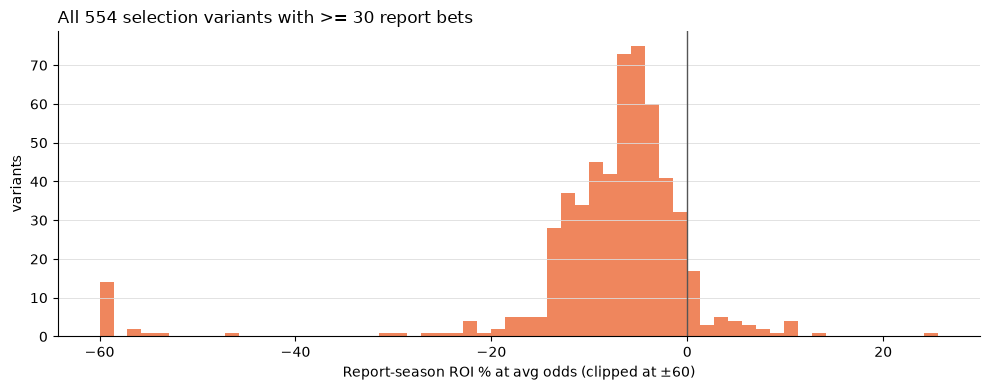

{'count': 554.0, 'mean': -8.87, 'std': 13.91, 'min': -100.0, '25%': -10.48, '50%': -6.18, '75%': -3.64, 'max': 25.6}


In [11]:
# Distribution of report-season ROI across all variants vs what pure luck around 0 would give
P, S = variant_matrix("avg", "report")
roi_all = P.sum(axis=1) / S.sum(axis=1) * 100
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(np.clip(roi_all, -60, 60), bins=60, color=REPORT_COLOUR, alpha=0.8)
ax.axvline(0, color="#555555", linewidth=1)
ax.set_xlabel("Report-season ROI % at avg odds (clipped at ±60)")
ax.set_ylabel("variants")
ax.set_title(f"All {len(roi_all)} selection variants with >= 30 report bets", loc="left")
style(ax)
plt.tight_layout()
plt.show()
print(roi_all.describe().round(2).to_dict())

## Stability of the leading strategy

**Leading strategy** = the pre-registered rule with the highest report-season ROI
at `avg`. This is a description, not a selection. Its ROI by league and season,
and its parameter neighbourhood: the same family and settings with the
threshold moved either side, tuning vs report. A real edge shouldn't hinge on one
exact threshold or one league.

In [12]:
lead_label = rep[(rep["source"] == "avg") & rep["rule"].isin(CHOSEN)].sort_values("roi", ascending=False).iloc[0]["rule"]
lead_ticket, lead_variant = CHOSEN[lead_label]
print("Leading pre-registered rule:", lead_label, "-", lead_variant)

lb = bets[(bets["rule"] == lead_variant) & (bets["source"] == "avg")]
def roi_ci(d, weeks):
    if d.empty:
        return pd.Series({"bets": 0, "ROI": np.nan, "CI": ""})
    boot = bootstrap_roi(week_frame(d, weeks))
    return pd.Series({"bets": len(d), "ROI": d["profit"].sum() / d["stake"].sum() * 100,
                      "CI": f"[{boot['ci'][0] * 100:+.1f}, {boot['ci'][1] * 100:+.1f}]"})

by_season = pd.DataFrame({s: roi_ci(lb[lb["Season"] == s], SEASON_WEEKS[s]) for s in TEST + [CURRENT]}).T
by_league = pd.DataFrame({
    (div, period): roi_ci(lb[(lb["Div"] == div) & lb["Season"].isin(PERIODS[period])], PERIOD_WEEKS[period])
    for div in sorted(lb["Div"].unique()) for period in PERIODS
}).T
display(by_season)
by_league["ROI"] = by_league["ROI"].astype(float).round(1)
by_league.unstack(1).swaplevel(axis=1)[[(p, c) for p in PERIODS for c in ["bets", "ROI", "CI"]]]

Leading pre-registered rule: P8-06 O/U - OU25 p>=0.675


,bets,ROI,CI
22-23,161,-0.192547,"[-13.2, +11.0]"
23-24,286,2.699301,"[-4.0, +9.5]"
24-25,200,-1.64,"[-9.6, +5.5]"
25-26,183,-4.612022,"[-12.8, +3.9]"
26-27,99,-4.191919,"[-12.9, +5.5]"


tune                       report                       26-27                      
    bets   ROI              CI   bets   ROI              CI  bets   ROI              CI
D1    86  -8.5   [-23.9, +5.6]    103   2.0  [-10.9, +14.0]    34  -7.2  [-32.4, +16.6]
E0    91   7.5   [-3.7, +19.4]     41 -10.4  [-36.0, +13.2]     2  45.5  [+36.0, +55.0]
F1    35   7.7  [-16.7, +29.3]     59  -7.9   [-26.0, +9.2]     6  -6.7  [-26.8, +32.1]
I1    11  18.1  [-22.4, +48.7]      7 -59.1  [-100.0, -2.4]     8  12.8  [-12.3, +53.4]
N1   122   2.1   [-8.2, +11.7]    101  -5.1   [-15.3, +5.7]    37  -7.9  [-29.1, +14.7]
P1    65  -6.9  [-25.7, +11.9]     31  22.7   [+5.4, +37.6]     5 -11.4  [-67.0, +40.0]
SP1   37  13.8  [-10.1, +34.6]     41  -6.3  [-27.4, +12.0]     7   3.9  [-21.3, +27.0]

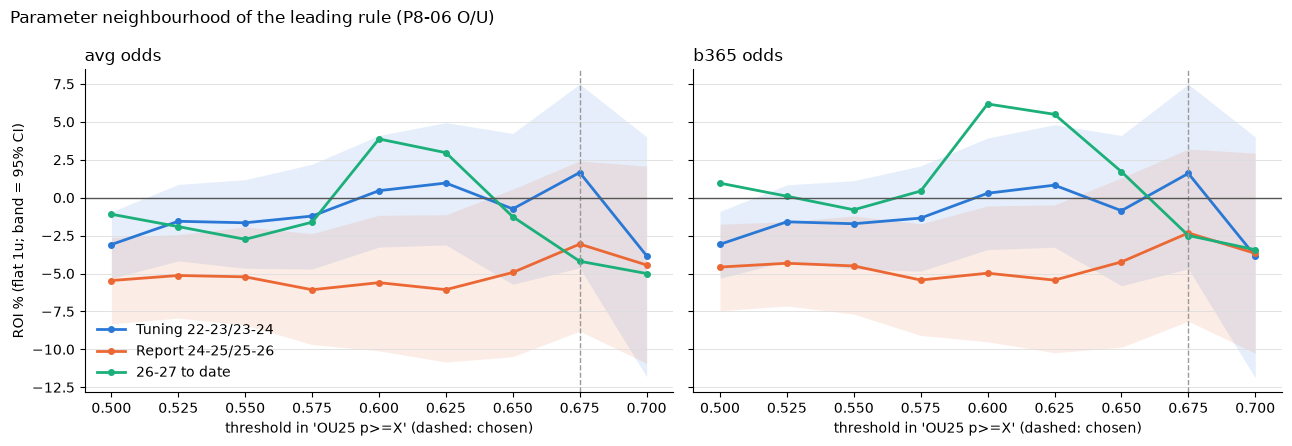

,bets,roi,bets,roi,bets,roi
period,tune,tune,report,report,26-27,26-27
param,,,,,,
0.500,4802.0,-3.1,4728.0,-5.5,640.0,-1.1
0.525,3766.0,-1.6,3838.0,-5.1,529.0,-1.9
0.550,2847.0,-1.7,2961.0,-5.2,436.0,-2.7
0.575,2081.0,-1.2,2188.0,-6.1,353.0,-1.6
0.600,1461.0,0.5,1501.0,-5.6,263.0,3.9
0.625,1021.0,1.0,973.0,-6.1,197.0,3.0
0.650,704.0,-0.7,595.0,-4.9,135.0,-1.3
0.675,447.0,1.7,383.0,-3.1,99.0,-4.2


In [13]:
# Parameter neighbourhood: same ticket, family and settings, threshold varied
pattern = re.sub(r">=[\d.]+", ">=X", lead_variant, count=1)
fam = selection[(selection["ticket"] == lead_ticket) & (selection["variant"] == lead_variant)]["family"].iloc[0]
nb = selection[(selection["ticket"] == lead_ticket) & (selection["family"] == fam)].copy()
nb = nb[nb["variant"].map(lambda v: re.sub(r">=[\d.]+", ">=X", v, count=1)) == pattern]
nb["param"] = nb["variant"].str.extract(r">=([\d.]+)")[0].astype(float)
lead_param = float(re.search(r">=([\d.]+)", lead_variant).group(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, source in zip(axes, ["avg", "b365"]):
    for period, colour, label in [("tune", TUNE_COLOUR, "Tuning 22-23/23-24"), ("report", REPORT_COLOUR, "Report 24-25/25-26"),
                                  ("26-27", CURRENT_COLOUR, "26-27 to date")]:
        d = nb[(nb["source"] == source) & (nb["period"] == period) & (nb["bets"] >= 30)].sort_values("param")
        if period != "26-27":
            ax.fill_between(d["param"], d["roi_ci_low"], d["roi_ci_high"], color=colour, alpha=0.12, linewidth=0)
        ax.plot(d["param"], d["roi"], color=colour, linewidth=2, marker="o", markersize=4, label=label)
    ax.axvline(lead_param, color="#999999", linestyle="--", linewidth=1)
    ax.axhline(0, color="#555555", linewidth=1)
    ax.set_title(f"{source} odds", loc="left")
    ax.set_xlabel(f"threshold in '{pattern}' (dashed: chosen)")
    style(ax)
axes[0].set_ylabel("ROI % (flat 1u; band = 95% CI)")
axes[0].legend(frameon=False, loc="lower left")
fig.suptitle(f"Parameter neighbourhood of the leading rule ({lead_label})", x=0.01, ha="left")
plt.tight_layout()
plt.show()
nb[nb["source"] == "avg"].pivot_table(index="param", columns="period", values=["roi", "bets"])[
    [("bets", "tune"), ("roi", "tune"), ("bets", "report"), ("roi", "report"), ("bets", "26-27"), ("roi", "26-27")]].round(1)

## What a season would look like

For the leading rule and the cheapest baseline (market favourite): resample one
season's worth of report-season weeks (5,000 times, seed 42) and record the season's
profit and its worst peak-to-trough drawdown. Flat 1 unit a bet, so with a
100-unit bank, 1 unit = 1% of the bank. These are the numbers behind "the chance of being
up after a season" and "the worst drawdown to expect".

In [14]:
def season_outlook(rule, source="avg", n=N_BOOT, seed=SEED):
    b = bets[(bets["rule"] == rule) & (bets["source"] == source)]
    w = week_frame(b[b["Season"].isin(REPORT)], PERIOD_WEEKS["report"])
    m = int(round(len(w) / len(REPORT)))
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(w), size=(n, m))
    prof, staked = w["profit"].to_numpy()[idx], w["staked"].to_numpy()[idx]
    cum = np.concatenate([np.zeros((n, 1)), np.cumsum(prof, axis=1)], axis=1)
    dd = (np.maximum.accumulate(cum, axis=1) - cum).max(axis=1)
    total = prof.sum(axis=1)
    return {"weeks/season": m, "bets/season": staked.sum(axis=1).mean(),
            "P(up after a season) %": (total > 0).mean() * 100,
            "season profit p5": np.percentile(total, 5), "p50": np.percentile(total, 50), "p95": np.percentile(total, 95),
            "season ROI p5 %": np.percentile(total / staked.sum(axis=1), 5) * 100,
            "season ROI p95 %": np.percentile(total / staked.sum(axis=1), 95) * 100,
            "max drawdown p50": np.percentile(dd, 50), "max drawdown p95": np.percentile(dd, 95)}

outlook = pd.DataFrame({label: season_outlook(CONTENDERS[label]) for label in [lead_label, "market favourite", "model argmax"]}).T
outlook.round(1)

,weeks/season,bets/season,P(up after a season) %,season profit p5,p50,p95,season ROI p5 %,season ROI p95 %,max drawdown p50,max drawdown p95
P8-06 O/U,38.0,189.3,23.0,-18.8,-5.6,6.9,-10.0,3.6,10.3,21.1
market favourite,38.0,2333.4,1.4,-157.4,-88.3,-21.3,-6.8,-0.9,98.7,164.8
model argmax,38.0,2333.4,0.0,-215.1,-139.0,-67.4,-9.2,-2.9,145.3,218.6


## Verdict

In [15]:
gate_avg_b365 = gate[["avg", "b365"]]
profitable = [r for r in gate.index if (gate_avg_b365.loc[r] == "profitable*").any()]
promising = [r for r in gate.index if r in CHOSEN and (gate_avg_b365.loc[r] == "promising").any()]
rc_report = mt[(mt["period"] == "report") & mt["source"].isin(["avg", "b365"])]
survives = (rc_report[["RC p", "SPA_c p"]] < 0.05).any(axis=None)
if profitable and survives:
    verdict = "PROFITABLE"
elif profitable or promising:
    verdict = "PROMISING"
else:
    verdict = "NO EDGE"
print("Verdict:", verdict)
print("  contenders at 'profitable*' before correction:", profitable or "none")
print("  pre-registered rules at 'promising':", promising or "none")
print("  RC / SPA_c p (report, avg / b365):", rc_report[["source", "RC p", "SPA_c p"]].round(3).to_dict("records"))

Verdict: NO EDGE
  contenders at 'profitable*' before correction: none
  pre-registered rules at 'promising': none
  RC / SPA_c p (report, avg / b365): [{'source': 'avg', 'RC p': 0.908, 'SPA_c p': 0.89}, {'source': 'b365', 'RC p': 0.895, 'SPA_c p': 0.886}]


## Findings

**Verdict: No edge.** None of the pre-registered rules or baselines makes money on the report seasons at
`avg` or `b365` odds. None is even "promising" (ROI > 0 in both report seasons and positive CLV). The best result
out of everything tried (~790 variants) is what luck alone would produce (Reality Check p = 0.91).
P8-08 (paper trading) doesn't happen. The effort should go back into the model.

**Shoot-out, report seasons 24-25/25-26, flat 1 unit, ROI % [95% week CI]:**

| Rule | avg | b365 | max | bets/wk | CLV avg | 24-25 / 25-26 (avg) | 26-27 avg |
|---|---|---|---|---|---|---|---|
| Market favourite | -3.8 [-6.4, -1.3] | -4.3 | -1.2 | 61 | -0.56 | -4.3 / -3.3 | -3.8 |
| Model argmax (what the site bets) | -6.0 [-8.8, -3.4] | -6.0 | -3.2 | 61 | -0.50 | -5.2 / -6.7 | -2.3 |
| Always draw | -3.2 [-8.0, +1.7] | -3.1 | +1.4 | 61 | +0.60 | -3.1 / -3.4 | -7.4 |
| P8-03 P1 picks p >= 0.475 | -5.5 [-14.2, +3.2] | -6.1 | -3.0 | 5.3 | +0.19 | -7.9 / -3.3 | -0.9 |
| P8-04 blended value, odds <= 2.5 | -3.4 [-8.3, +1.1] | -5.6 [-9.9, -1.1] | -0.8 | 15.9 | +0.08 | -3.2 / -4.4 | -5.4 (10 bets) |
| P8-05 top-8 acca, odds >= 1.50 | -100 (0 of 76 won) | -49.0 | -46.6 | 1.0 | -0.12 | -100 / -100 | -100 |
| **P8-06 O/U fair p >= 0.675** | **-3.1 [-8.8, +2.4]** | -2.3 [-8.1, +3.2] | -0.8 | 5.0 | +0.25 | -1.6 / -4.6 | -4.2 |
| P8-06 AH fair p >= 0.675 | -13.2 [-28.1, +2.8] | -11.4 | -11.6 | 1.4 | -1.33 | -23.8 / +3.5 | -27.3 |

Always home -10.1 and always away -10.1 at avg. Every pre-registered rule was positive or about zero in tuning
(P8-03 +6.1, O/U +1.7, AH +5.8, P8-05 +211) and negative in the report seasons. No contender was in profit in both
report seasons at any source, except "always draw" at `max`, which is a best-price bound and not a strategy.

**Multiple testing:**
- *Pre-registered rules* (5 rules x {avg, b365} = 10 tests, Bonferroni 99.5% CI): every point estimate is
  negative. One-sided p(ROI > 0) is 0.63-1.00 before correction, so 1.00 after it. Nothing to correct.
- *Best of everything* (selection variants with >= 30 report bets: 554 at avg, 557 b365, 585 max; 788 selection
  variants + 18 staking runs logged in total). At avg, 39 of 554 are positive in report. The best is a threshold
  acca (all picks p >= 0.70) at +25.6%, which was -18% in tuning and -52% in 26-27. **White's RC p = 0.91 (avg),
  0.90 (b365), 0.44 (max); Hansen SPA_c p = 0.89 / 0.89 / 0.66.** The best report result is fully explained by luck.
  The median variant lost 6.2%.
- *Tuning seasons* (what each ticket's selection rewarded): best = the P8-05 acca at +211% (one winning acca).
  RC p = 0.26 and SPA_c p = 0.72 at avg. The "winners" picked on tuning were never distinguishable from noise.
- *26-27 to date* (11 weeks): SPA flags Serie A confidence thresholds (I1 p >= 0.525: +39%), but RC p = 0.28-0.44.
  With 11 weeks the bootstrap standard errors are unreliable, and the pattern was found after the fact. Note it,
  don't act on it. P8-03's I1 thresholds lost in the report seasons.

**Stability of the leading rule** (O/U 2.5 fair p >= 0.675, the least-bad pre-registered rule at avg):
- By season: -0.2 / +2.7 (tuning) → -1.6 / -4.6 (report) → -4.2 (26-27), so it's drifting down.
- By league (report): only P1 is clearly positive (+22.7 [+5.4, +37.6], 31 bets) and D1 +2.0. I1 -59, E0 -10.
  The tuning leaders (E0, SP1, I1) all flipped.
- Neighbourhood: at avg, report ROI is -3 to -6% at every threshold from 0.50 to 0.70. 0.675 is the top of a noisy
  curve, not a plateau. Tuning ROI is about 0 everywhere. The report curve is negative at every threshold.

**Plain-English summary for the owner:**
- **What to bet:** nothing, for money. No rule found in P8-03..06 beats the bookmaker's margin, and the best one
  only looked good by chance.
- **If you bet anyway** (the least-bad rule, O/U 2.5 when our goals model gives a side >= 67.5%, about 5 bets a
  week, 1 unit = 1% of a 100-unit bank): expect around -3% ROI (95% range -9% to +2%). The chance of being up
  after a season is **about 23%**. A typical season ends about -6 units (5-95%: -19 to +7). Expect a worst
  drawdown of about 10 units in a typical season and 21 units in a bad one (95th percentile).
- **Betting every model pick** (what the site's record does): -6% in the report seasons, about a 0% chance of a
  winning season at 60 bets a week, and a typical drawdown of about 145 units a season. Backing the market
  favourite instead loses less (-3.8%) but still loses.
- The only positive-expectation idea in Phase 8 was bookmaker promotions ("one leg lets you down" acca refunds,
  P8-05). That comes from the bookmaker's offer, not from the model, and it's out of scope here.
- **Next:** close the log-loss gap to the market (P8-02: +0.021, with draws spread too flat and strong favourites
  rated too low) or use the market price as a model input, rather than searching for more strategies.